In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [3]:
import kagglehub

path = kagglehub.dataset_download("gauravduttaiiitb/irrigation-water-requirement")

print("Path to dataset files:", path)

100%|██████████| 342k/342k [00:00<00:00, 29.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/gauravduttaiiitb/irrigation-water-requirement/versions/1


In [4]:
import os
import pandas as pd

file_path = os.path.join(path, "irrigation_prediction.csv")

df = pd.read_csv(file_path)

print(df.head())

print(df.columns)

  Soil_Type  Soil_pH  Soil_Moisture  Organic_Carbon  Electrical_Conductivity  \
0      Clay     6.14          36.48            0.42                     2.17   
1      Silt     6.41          50.56            0.38                     0.23   
2     Sandy     7.71          40.07            1.09                     2.18   
3      Clay     5.96          12.75            1.56                     0.40   
4      Clay     7.76          18.58            0.95                     2.52   

   Temperature_C  Humidity  Rainfall_mm  Sunlight_Hours  Wind_Speed_kmh  \
0          21.90     31.19      1167.70            4.01            1.97   
1          36.50     26.01       831.28           10.72           16.82   
2          41.83     76.41      1844.45            7.75           19.03   
3          37.22     43.32       306.26            8.90           11.44   
4          22.38     86.44      1875.63           10.39           11.26   

  Crop_Type Crop_Growth_Stage  Season Irrigation_Type Water_Source  

In [5]:

print(df.isnull().sum())

Soil_Type                  0
Soil_pH                    0
Soil_Moisture              0
Organic_Carbon             0
Electrical_Conductivity    0
Temperature_C              0
Humidity                   0
Rainfall_mm                0
Sunlight_Hours             0
Wind_Speed_kmh             0
Crop_Type                  0
Crop_Growth_Stage          0
Season                     0
Irrigation_Type            0
Water_Source               0
Field_Area_hectare         0
Mulching_Used              0
Previous_Irrigation_mm     0
Region                     0
Irrigation_Need            0
dtype: int64


In [6]:
print(df.select_dtypes(include="number").columns)

Index(['Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity',
       'Temperature_C', 'Humidity', 'Rainfall_mm', 'Sunlight_Hours',
       'Wind_Speed_kmh', 'Field_Area_hectare', 'Previous_Irrigation_mm'],
      dtype='object')


In [7]:
df["Irrigation_Need_Score"] = df["Irrigation_Need"].map({
    "Low": 0,
    "Medium": 1,
    "High": 2
})
X = df.drop(columns=["Irrigation_Need", "Irrigation_Need_Score"])
y = df["Irrigation_Need_Score"]
print(y.head())

0    0
1    1
2    0
3    1
4    1
Name: Irrigation_Need_Score, dtype: int64


In [8]:
X = pd.get_dummies(X, drop_first=True)

print("X shape:", X.shape)

X shape: (10000, 35)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 35)
Testing data: (2000, 35)


In [10]:
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [11]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[ 0.37022721  0.74968012  1.48744057 -0.02594295  0.16370368  0.7342263
  0.21571818  0.35368996  0.68367603  0.28231787]


In [12]:
for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print("Actual:", actual, "| Predicted:", round(predicted, 2))

Actual: 0 | Predicted: 0.37
Actual: 1 | Predicted: 0.75
Actual: 2 | Predicted: 1.49
Actual: 0 | Predicted: -0.03
Actual: 0 | Predicted: 0.16
Actual: 1 | Predicted: 0.73
Actual: 0 | Predicted: 0.22
Actual: 0 | Predicted: 0.35
Actual: 1 | Predicted: 0.68
Actual: 0 | Predicted: 0.28


In [13]:
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R² Score:", r2)

Mean Absolute Error: 0.29484758344869316
R² Score: 0.5686264788821098


In [14]:
new_data = X_test.iloc[[0]]
prediction = model.predict(new_data)[0]

print("Predicted irrigation score:", round(prediction, 2))

Predicted irrigation score: 0.37


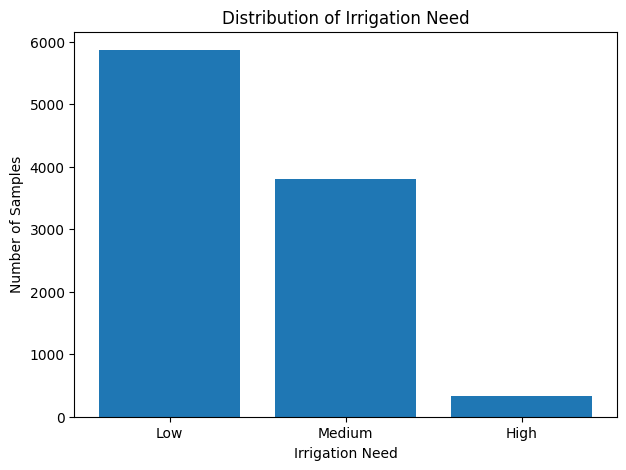

In [16]:
import matplotlib.pyplot as plt

counts = df["Irrigation_Need"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(counts.index, counts.values)

plt.xlabel("Irrigation Need")
plt.ylabel("Number of Samples")
plt.title("Distribution of Irrigation Need")

plt.show()